In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

### 1.- Pedidos por mes ptl.plot

,order_purchase_timestamp,order_id,month
63579,2018-03-15 12:49:58,36cad69053608ab058c6d470d4be06a1,2018-03
75006,2018-04-29 15:17:48,576d9e6af8fd6888f42db26fb8bfc21a,2018-04
56954,2018-03-26 11:52:14,18914d929964317dc0a002fcbbd70d06,2018-03
68408,2017-06-01 19:58:20,d6ee6e570c72b3abf832d6427e06627e,2017-06
78786,2018-05-18 16:32:06,1084873135af1b72eb54613119a6604f,2018-05


<Axes: title={'center': 'Numero de ventas por mes'}, xlabel='mes', ylabel='Cantidad de ventas'>

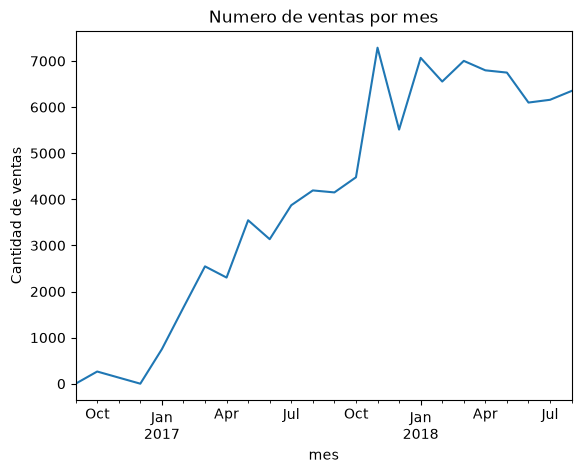

In [17]:
df1 = orders[orders["order_status"] == "delivered"]
df1 = df1[["order_purchase_timestamp","order_id"]]
df1["month"] = df1["order_purchase_timestamp"].dt.to_period('M')
display(df1.sample(5))
resultado = df1.groupby("month")["order_id"].nunique()
resultado.plot(
    kind = "line",
    xlabel = "mes",
    ylabel = "Cantidad de ventas",
    title = "Numero de ventas por mes"
)

### 2.-Top 10 categorías por ingreso ptl.barh

<Axes: ylabel='product_category_name'>

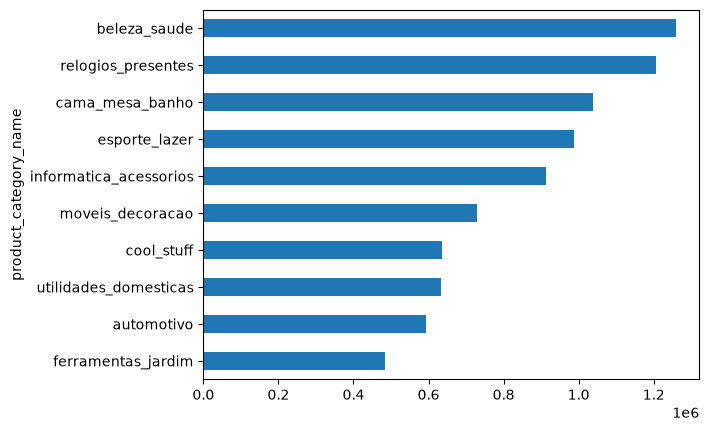

In [32]:
df1 = order_items[["product_id","price"]]
df2 = products[["product_id","product_category_name"]]
df3 = df2.merge(df1, on = "product_id", how = "left")
resultado2 = df3.groupby("product_category_name")["price"].sum().nlargest(10).sort_values(ascending = True)
resultado2.plot(
    kind = "barh"
)

### 3.-Distribución del precio ptl.hist

<Axes: ylabel='Frequency'>

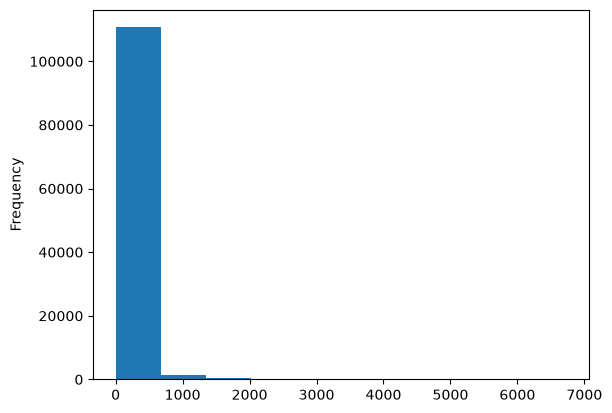

In [19]:
df1 = order_items["price"]
df1.plot(
    kind = "hist"
)

<Axes: >

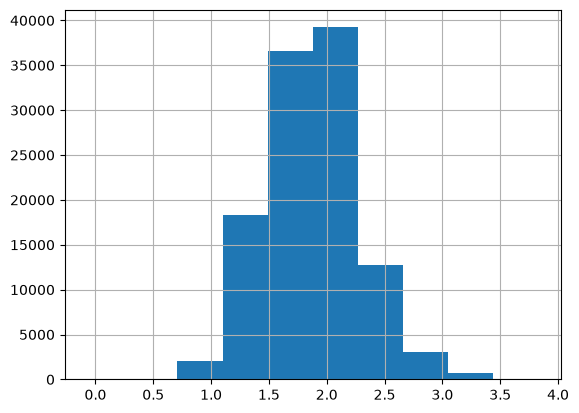

In [20]:
import numpy as np
df5 = order_items
df5["log"] = df5["price"].apply(np.log10)
df5["log"].hist()

### 4.-Días de entrega reales vs estimado hist + alpha

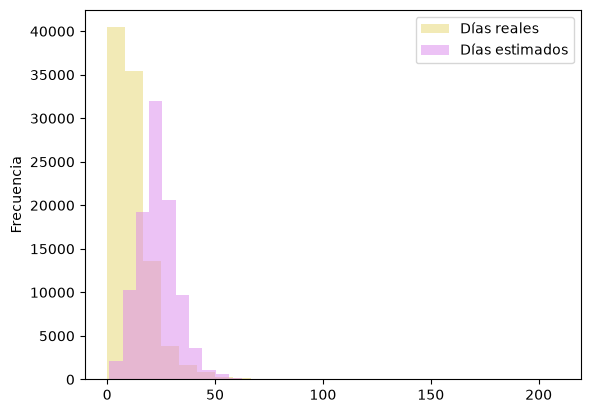

In [21]:
dias_reales = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
dias_estimados = (orders["order_estimated_delivery_date"] - orders["order_purchase_timestamp"]).dt.days
dias_reales = dias_reales.dropna()
dias_estimados = dias_estimados.dropna()
ax1 = dias_reales.plot(
    kind = "hist",
    color ="#e7d76e",
    alpha = 0.5,
    bins = 25,
    label = "Días reales",
    ylabel = "Frecuencia"
)
ax2 = dias_estimados.plot(
    kind= "hist",
    color ="#db86ec",
    alpha = 0.5,
    bins = 25,
    label = "Días estimados",
    ylabel = "Frecuencia"
)
ax1.legend()
plt.show()

### 5.-Calificación vs dás de retraso ptl.boxplot

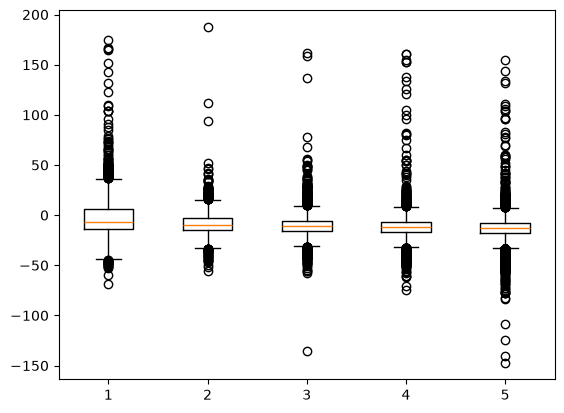

In [34]:
orders["retraso"] = (orders["order_delivered_customer_date"]-orders["order_estimated_delivery_date"]).dt.days
merge = orders.merge(order_reviews, on = "order_id", how = "left").drop_duplicates(subset="order_id")
merge = merge.dropna(subset="retraso")
lista = [merge[merge["review_score"] == calif]["retraso"] for calif in range(1, 6)]
fig, ax = plt.subplots()
ax.boxplot(lista,label=[1,2,3,4,5])
plt.show()

### 6.-Califiación promedio a tiempo vs tarde ptl.bar

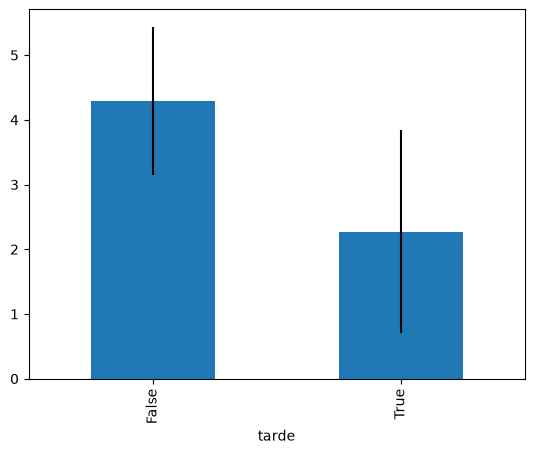

In [23]:
merge["tarde"] = (merge["retraso"]>0)
merge = merge.dropna(subset="retraso")
tarde_con_review = merge.groupby("tarde")["review_score"].agg(["mean","std"])
ax3 = tarde_con_review["mean"].plot(kind="bar",
                            yerr = tarde_con_review["std"])

### 7.-Métodos de pago ptl.pie

<Axes: >

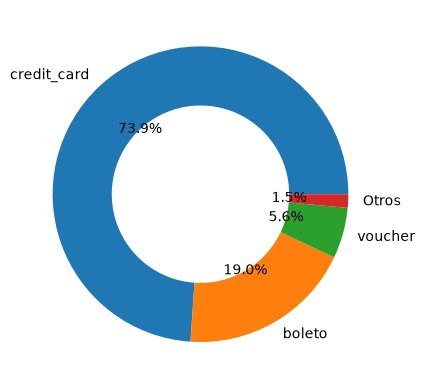

In [35]:
df8 = payments["payment_type"].value_counts().head(3)
df8["Otros"] = payments["payment_type"].value_counts().iloc[3:].sum()
df8.plot(kind = "pie",
         autopct="%1.1f%%",
         wedgeprops={"width":0.4})

### 8.-Monto promedio de mensualidades y método de pago pivot + bar

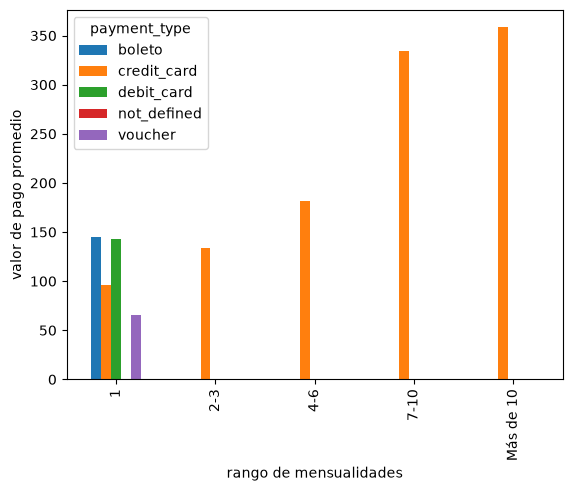

In [26]:
payments["rangos"] = pd.cut(payments["payment_installments"],
                            bins=[0,1,3,6,10,np.inf],
                            labels = ["1","2-3","4-6","7-10","Más de 10"])
pibble = payments.pivot_table(index="rangos",columns="payment_type",values="payment_value",aggfunc="mean")
pibble.plot(kind="bar", 
            ylabel = "valor de pago promedio",
            xlabel = "rango de mensualidades")
plt.show()

### 9.-Estado del pedido por estado de la república pivot + bottom

<Axes: xlabel='Estado de orden', ylabel='Proporcion de pedidos'>

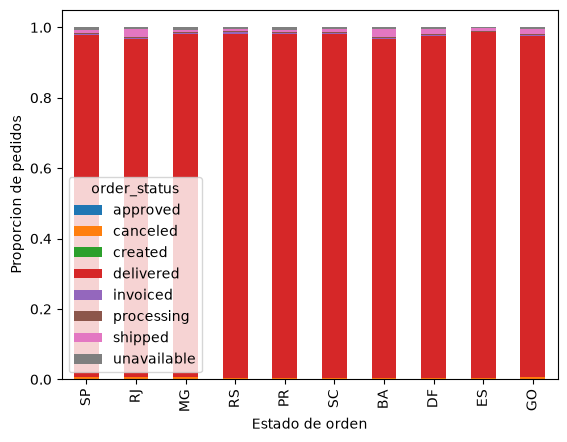

In [27]:
merge1 = orders.merge(customers, on="customer_id", how = "left")
pibble_2 = merge1.pivot_table(index = "customer_state",columns = "order_status",values= "order_id",aggfunc="count",fill_value=0)
pibble2_suma = pibble_2.sum(axis=1)
pibble2_division = pibble_2.div(pibble2_suma,axis=0)
pibble2_division_10 = pibble2_division.loc[pibble2_suma.nlargest(10).index]
pibble2_division_10.plot(kind="bar",
                         stacked="True",
                         xlabel="Estado de orden",
                         ylabel = "Proporcion de pedidos")

### 10.-Peso del producto vs costo de envío ptl.scatter

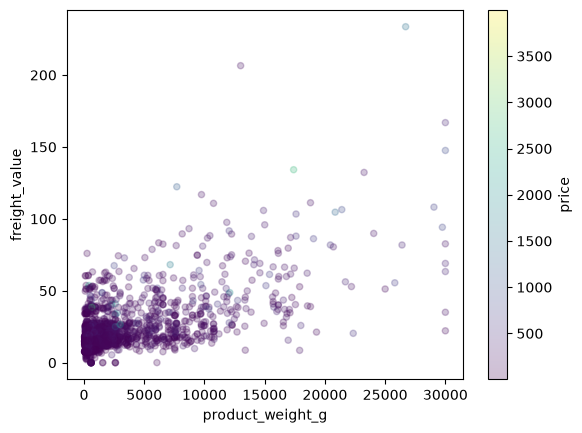

In [29]:
merge = order_items.merge(products,on="product_id",how="left")
merge_sinNANS = merge[["product_weight_g","freight_value","price"]].dropna()
merge_sample = merge_sinNANS.sample(3000)
merge_sample.plot(kind="scatter",
                   x="product_weight_g",
                   y="freight_value",
                   c="price",
                   alpha = 0.25)
plt.show()

### 11.-Pedidos por día de la semana x hora pivot + imshow

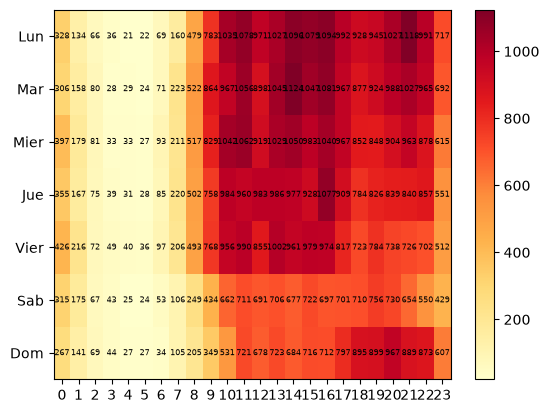

In [30]:
orders["dias_semana"] = orders["order_purchase_timestamp"].dt.dayofweek
orders["horas"] = orders["order_purchase_timestamp"].dt.hour
pibble3 =  orders.pivot_table(index ="dias_semana", columns = "horas", values= "order_id",aggfunc="count")
mapa = plt.imshow(pibble3,aspect="auto",cmap ="YlOrRd" )
plt.yticks(range(7),["Lun","Mar","Mier","Jue","Vier","Sab","Dom"])
plt.xticks(range(24))
plt.colorbar(mapa)
for i in range(7):
    for j in range(24):
        plt.text(j, i, pibble3.iloc[i, j],  ha="center", va="center",fontsize=6)

### 12.-Suplot + doble eje ptl.subplots + twinx

(Text(0.5, 0.98, 'ejercicio 12'), None, None)

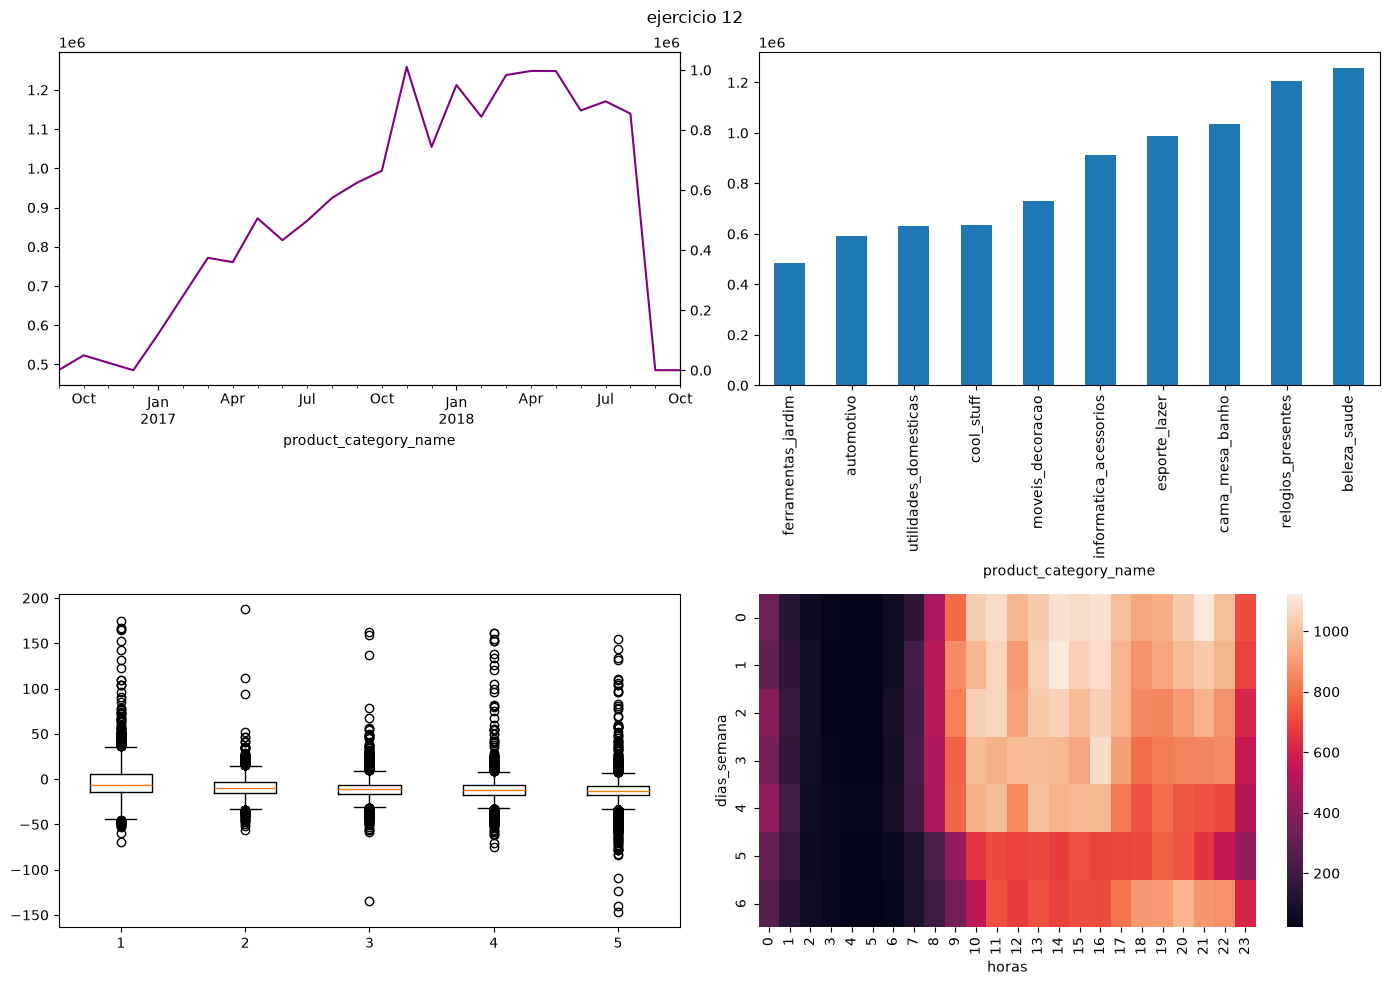

In [41]:
uno = resultado
dos = resultado2
cinco = lista
once = pibble3
fig, axes = plt.subplots(2,2,figsize=(14,10))
uno.plot(ax=axes[0,0])
ingreso_mensual = orders.merge(order_items, on = "order_id", how = "left")
ingreso_mensual["month"] = ingreso_mensual["order_purchase_timestamp"].dt.to_period('M')
ingreso = ingreso_mensual.groupby("month")["price"].sum()
ax2 = axes[0,0].twinx()
ingreso.plot(ax=ax2, color="purple")
dos.plot(kind = "bar",
         ax=axes[0,1])
axes[1,0].boxplot(cinco,label=[1,2,3,4,5])
sns.heatmap(once,ax=axes[1,1])
fig.suptitle("ejercicio 12"), plt.tight_layout(), plt.savefig('dashboard.png', dpi=150)